# Predicting King County house prices with a neural network

**Team:** Karthikeyan Saravanan, Emmanuel Marquez, Bars Babila, Samiha Abeda Nur
**Course:** AI Methods I – Day 4: Neural networks and computer vision (IAAC MaAI 2026/27)
**Track:** A1 – a multilayer perceptron (MLP) on tabular data

On Day 2 we predicted the sale price of a house in King County (Washington, USA) with classic machine-learning models, and gradient boosting won. Today we train a **neural network** on **exactly the same data, inputs, target and test set**, and ask one question: **is the network better than our Day 2 model?**

# 0. Introduction and problem definition

## 0.1 Use case: the three questions of the brief

- **Who would use this model, and for what?** Real estate professionals, buyers and lenders who want a **quick first estimate** of what a house in King County is worth, from a few facts about the building and its location, before a full professional valuation. This is the same use case as our Day 2 model.
- **What does a mistake cost?** Over-estimating the price can make a buyer overpay or a lender lend too much; under-estimating it can make a seller sell too cheaply. Both directions are costly, and an error of 50,000 USD matters much more for a 250,000 USD house than for a 1,500,000 USD one. So we care about the error **in percent**, not in dollars. This is why we predict `log10(price)`, as on Day 2, and report the error as a typical percentage.
- **What would be good enough?** We compare the network with two models on the same test set: a **dummy model** that always predicts the average price (the floor), and our **Day 2 gradient boosting model** (the bar to beat). A network that only matches the Day 2 model would still be a useful result: it tells us whether the extra work of deep learning pays off on this kind of data.

## 0.2 The data

We use [House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) (Kaggle, licence CC0 1.0, public domain), as cleaned in our [Day 1 / Day 2 assignment](https://github.com/iaac-maai/2-day2-assignment). It contains **20,703 sales** of houses in King County, which includes Seattle, between May 2014 and May 2015, with 19 columns. **One example is one sale**: one row with the building's characteristics, its location and its sale price.

The Day 1 cleaning converted the dates, removed the `waterfront` and `view` columns (mostly zeros) and filtered extreme prices, living areas and bedroom counts. We do not clean the data again: using the **same rows** as on Day 2 is what makes the comparison fair.

## 0.3 Setup

The notebook lives in `notebook/`, so the other folders are **one level up**: all paths are relative and start from `Path("..")`. A fixed `RANDOM_STATE = 42` is used everywhere randomness is involved, including PyTorch, so a re-run gives the same results.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install -r ../requirements.txt

In [2]:
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [3]:
# --- Folders (the notebook lives in notebook/, the rest is one level up) ------
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as Days 1-3) ----------------------------
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# --- The same seed everywhere -------------------------------------------------
# Networks start from random weights, so fixing the seed gives everybody the same results
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# --- Which processor will train the network? ----------------------------------
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name, also_to_models=False):
    # Save the current figure as a PNG in figures/ (and in models/ if it goes in the model card)
    for folder in [FIG_DIR] + ([MODEL_DIR] if also_to_models else []):
        path = folder / f"{name}.png"
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Figure saved to {path}")

PyTorch 2.14.1, using device: mps


# 1. Data and splits

## 1.1 Load the data

We load the cleaned file from our public Day 2 repository. The first time, the notebook downloads it and stores a copy in `data/` (which is not committed to GitHub).

In [4]:
CLEAN_URL = "https://raw.githubusercontent.com/iaac-maai/2-day2-assignment/main/data/kc_houses_data_clean.csv"
CLEAN_PATH = DATA_DIR / "kc_houses_data_clean.csv"

if not CLEAN_PATH.exists():
    pd.read_csv(CLEAN_URL).to_csv(CLEAN_PATH, index=False)
    print(f"Downloaded to {CLEAN_PATH}")

houses = pd.read_csv(CLEAN_PATH, parse_dates=["date"])
print(f"{houses.shape[0]:,} sales, {houses.shape[1]} columns")
print(f"Sales from {houses['date'].min():%Y-%m-%d} to {houses['date'].max():%Y-%m-%d}")
print(f"Missing values: {houses.isna().sum().sum()}, duplicated rows: {houses.duplicated().sum()}")
houses.head()

20,703 sales, 19 columns
Sales from 2014-05-02 to 2015-05-27
Missing values: 0, duplicated rows: 0


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,"221,900.000",3,1.000,1180,5650,1.000,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,2014-12-09,"538,000.000",3,2.250,2570,7242,2.000,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,2015-02-25,"180,000.000",2,1.000,770,10000,1.000,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,2014-12-09,"604,000.000",4,3.000,1960,5000,1.000,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,2015-02-18,"510,000.000",3,2.000,1680,8080,1.000,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


## 1.2 Inputs and target: the same as on Day 2

To compare the network with our Day 2 model fairly, we keep **every choice of Day 2**:

- **Target:** `log10(price)`. Prices are right-skewed, and an error on the log scale is an error in **percent** (see the use case). A log10 error of 0.05 means a factor of 10^0.05 = 1.12, so the prediction is about 12% too high or too low.
- **Inputs (13 columns):** the building (`bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`, `condition`, `grade`, `sqft_basement`, `yr_built`, `yr_renovated`) and its location (`zipcode`, `lat`, `long`).
- **Dropped, as on Day 2:** `id` and `date` (identifiers, not characteristics), `sqft_above` (= `sqft_living − sqft_basement`, so it repeats information), and `sqft_living15` / `sqft_lot15` (they describe the neighbours, not the house).

In [5]:
TARGET = "price"
NUMERIC_COLUMNS = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                   "condition", "grade", "sqft_basement", "yr_built", "yr_renovated",
                   "lat", "long"]
NOMINAL_COLUMNS = ["zipcode"]
INPUT_COLUMNS = NUMERIC_COLUMNS + NOMINAL_COLUMNS

X = houses[INPUT_COLUMNS]
y = np.log10(houses[TARGET])          # the target: log10 of the price in USD
groups = houses["id"]                 # only used to build the splits, not as an input

print(f"X: {X.shape[0]:,} rows x {X.shape[1]} columns")
print(f"Skewness of price: {houses[TARGET].skew():.2f}, of log10(price): {y.skew():.2f}")
X.describe().T

X: 20,703 rows x 13 columns
Skewness of price: 1.72, of log10(price): 0.28


,count,mean,std,min,25%,50%,75%,max
bedrooms,"20,703.000",3.381,0.836,2.000,3.000,3.000,4.000,6.000
bathrooms,"20,703.000",2.108,0.715,0.500,1.750,2.250,2.500,5.250
sqft_living,"20,703.000","2,053.138",799.705,720.000,"1,445.000","1,920.000","2,520.000","4,970.000"
sqft_lot,"20,703.000","14,649.509","39,056.371",520.000,"5,027.000","7,579.000","10,500.000","1,651,359.000"
floors,"20,703.000",1.496,0.540,1.000,1.000,1.500,2.000,3.500
condition,"20,703.000",3.413,0.647,1.000,3.000,3.000,4.000,5.000
grade,"20,703.000",7.647,1.086,4.000,7.000,7.000,8.000,13.000
sqft_basement,"20,703.000",284.345,422.543,0.000,0.000,0.000,560.000,"2,350.000"
yr_built,"20,703.000","1,971.491",29.151,"1,900.000","1,952.000","1,976.000","1,997.000","2,015.000"
yr_renovated,"20,703.000",81.946,396.053,0.000,0.000,0.000,0.000,"2,015.000"


We look at the target before and after the log. The right panel is what the network will learn to predict.

Figure saved to ../figures/00_target_distribution.png


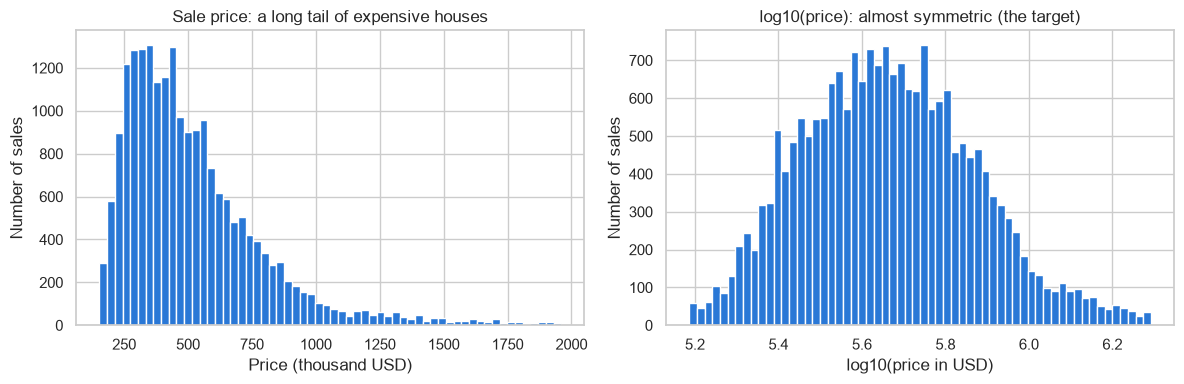

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(houses[TARGET] / 1000, bins=60, color="#2a78d6")
axes[0].set(title="Sale price: a long tail of expensive houses", xlabel="Price (thousand USD)", ylabel="Number of sales")
axes[1].hist(y, bins=60, color="#2a78d6")
axes[1].set(title="log10(price): almost symmetric (the target)", xlabel="log10(price in USD)", ylabel="Number of sales")
plt.tight_layout()
save_fig("00_target_distribution")
plt.show()

**Reading.** The raw price has a long tail to the right (skewness 1.72, against 0.28 after the log): a few expensive houses would dominate a squared-error loss. On the log scale the distribution is close to symmetric, so every house counts in proportion to its price. Most sales lie between log10 = 5.4 and 6.0, that is between about 250,000 and 1,000,000 USD.

## 1.3 Split before anything else

The brief asks for a **training**, a **validation** and a **test** set, and for **the same test set as our Day 2 model**.

- **Test set (20%) – exactly the Day 2 split.** Day 2 used `GroupShuffleSplit(test_size=0.2, random_state=42)` with the house `id` as the group: 148 houses were sold twice, and both sales must stay on the same side of the split, or the model would be tested on a house it has already seen. We repeat this call with the same data, so we get **the same 4,147 test sales** as on Day 2. The test set is then locked away until section 6.
- **Validation set (20% of the rest).** A network is trained for many epochs, so we need a separate set to watch the training, choose when to stop and compare settings (sections 3 to 5). We cut it from the Day 2 training set in the same way, grouped by `id`.

In [7]:
# 1) The Day 2 split: same call, same data, same random_state -> same test set
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(outer.split(X, y, groups))

# 2) Validation set: 20% of the Day 2 training set, again grouped by house id
inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_pos, val_pos = next(inner.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[train_pos], trainval_idx[val_pos]

X_trainval, y_trainval = X.iloc[trainval_idx], y.iloc[trainval_idx]   # = the Day 2 training set
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]                   # locked away until section 6

split_sizes = pd.DataFrame({
    "sales": [len(train_idx), len(val_idx), len(test_idx)],
    "share": [len(train_idx) / len(X), len(val_idx) / len(X), len(test_idx) / len(X)],
    "median price (USD)": [10 ** y_train.median(), 10 ** y_val.median(), 10 ** y_test.median()],
}, index=["train", "validation", "test"])

# Checks: the same test set as Day 2 (4,147 sales), and no house on two sides of a split
assert len(test_idx) == 4147 and len(trainval_idx) == 16556, "not the Day 2 split"
sets = {name: set(groups.iloc[idx]) for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("Same test set as Day 2: 4,147 sales. No house appears in two sets.")
split_sizes.style.format({"sales": "{:,}", "share": "{:.1%}", "median price (USD)": "{:,.0f}"})

Same test set as Day 2: 4,147 sales. No house appears in two sets.


,sales,share,median price (USD)
train,"13,244",64.0%,"450,000"
validation,"3,312",16.0%,"459,700"
test,"4,147",20.0%,"450,000"


**Reading.** 13,244 sales for training (64%), 3,312 for validation (16%) and 4,147 for the test (20%). The median price is almost the same in the three sets (450,000, 459,700 and 450,000 USD), so none of them is cheaper or more expensive by accident.

## 1.4 Preprocessing: scaled numbers and a one-hot ZIP code

A neural network is very sensitive to the **scale** of its inputs: without scaling, `sqft_lot` (values up to about 1,000,000) would dominate `bathrooms` (1 to 5). So:

- the **12 numeric columns** are standardised with a `StandardScaler` (mean 0, standard deviation 1);
- **`zipcode`** is a category, not a quantity (98103 is not "bigger" than 98023), so it is **one-hot encoded**, as on Day 2: one 0/1 column per ZIP code.

The preprocessor is **fitted on the training set only**: the validation and test sets are transformed with the training statistics, so no information leaks from them. This fitted object is what we will publish next to the weights as `scaler.joblib` (section 8): a user must prepare a new house in exactly the same way.

In [8]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_COLUMNS),
    ("zipcode", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL_COLUMNS),
])
preprocess.fit(X_train)                                  # learned on the training set only

N_INPUTS = len(preprocess.get_feature_names_out())
print(f"{len(NUMERIC_COLUMNS)} scaled numeric columns + {N_INPUTS - len(NUMERIC_COLUMNS)} ZIP-code columns "
      f"= {N_INPUTS} inputs to the network")

check = pd.DataFrame(preprocess.transform(X_train)[:, :len(NUMERIC_COLUMNS)], columns=NUMERIC_COLUMNS)
check.describe().loc[["mean", "std"]].round(3)

12 scaled numeric columns + 70 ZIP-code columns = 82 inputs to the network


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_basement,yr_built,yr_renovated,lat,long
mean,0.000,0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


## 1.5 Convert to tensors

PyTorch works with **tensors**: `float32` for the inputs, and the target as a column of shape `(n, 1)`, because the network will have **one output neuron** (one predicted value per house).

In [9]:
def to_tensors(X_part, y_part):
    # Preprocessed inputs as float32, target log10(price) as a float32 column (n, 1)
    return (torch.tensor(preprocess.transform(X_part), dtype=torch.float32),
            torch.tensor(y_part.to_numpy(), dtype=torch.float32).reshape(-1, 1))


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)          # used once, in section 6
print(f"train {tuple(X_train_t.shape)}, validation {tuple(X_val_t.shape)}, test {tuple(X_test_t.shape)}")

train (13244, 82), validation (3312, 82), test (4147, 82)


# 2. Baseline

The network must beat something to be worth its extra complexity. We use two baselines, both evaluated with the same metrics:

1. **Dummy model:** always predicts the average `log10(price)` of the training set. It knows nothing about the houses; any useful model must be far better.
2. **Our Day 2 model:** `HistGradientBoostingRegressor` with its default settings, inside the Day 2 pipeline (median imputation, one-hot ZIP code, no scaling: trees do not need it). It was the model we selected on Day 2.

**Metrics** (on `log10(price)`, the same as Day 2):
- **R²**: the share of the variation in log-prices explained by the model (1 = perfect, 0 = no better than the average).
- **MAE (log10)** and the **typical error in %** it implies: 10^MAE − 1.
- **MAE in USD**, after converting the predictions back to prices, for readers who think in dollars.

We evaluate each baseline twice:
- on the **validation set**, after fitting on the training set only: this is the number the network will be compared with in sections 3 to 5, without touching the test set;
- on the **test set**, after fitting on the whole Day 2 training set (training + validation), exactly as on Day 2. This reproduces our published Day 2 result, and is the number the network's final test score will be compared with in section 6.

In [10]:
def evaluate(y_true_log, y_pred_log):
    # The metrics used in this notebook, from true and predicted log10(price)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    return {
        "R² (log10)": r2_score(y_true_log, y_pred_log),
        "MAE (log10)": mae_log,
        "typical error (%)": (10 ** mae_log - 1) * 100,
        "MAE (USD)": mean_absolute_error(10 ** y_true_log, 10 ** y_pred_log),
    }


def day2_model():
    # The Day 2 pipeline: median imputation + one-hot ZIP code + gradient boosting (default settings)
    return Pipeline([
        ("preprocess", ColumnTransformer([
            ("numeric", SimpleImputer(strategy="median"), NUMERIC_COLUMNS),
            ("zipcode", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
             NOMINAL_COLUMNS),
        ])),
        ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    ])


baselines = {"Dummy (mean price)": lambda: DummyRegressor(strategy="mean"),
             "Day 2: gradient boosting": day2_model}

rows = []
for name, make in baselines.items():
    # Validation: fit on the training set only
    on_val = make().fit(X_train, y_train)
    rows.append({"model": name, "evaluated on": "validation", **evaluate(y_val, on_val.predict(X_val))})
    # Test: fit on the whole Day 2 training set, as on Day 2
    on_test = make().fit(X_trainval, y_trainval)
    rows.append({"model": name, "evaluated on": "test", **evaluate(y_test, on_test.predict(X_test))})
    if name.startswith("Day 2"):
        day2_final = on_test                                  # kept for the comparison in section 6

baseline_results = pd.DataFrame(rows).set_index(["model", "evaluated on"])
baseline_results.style.format({"R² (log10)": "{:.3f}", "MAE (log10)": "{:.4f}",
                               "typical error (%)": "{:.1f}", "MAE (USD)": "{:,.0f}"})

**Reading.**

- **We reproduce our Day 2 result:** on the Day 2 test set, gradient boosting reaches **R² = 0.886**, exactly the test score we published on Day 2. This confirms that the test set and the model are the same.
- **The bar to beat:** on the test set the Day 2 model is typically **12.2% off** the true price (a mean error of about 60,200 USD), against **47.0%** (about 196,300 USD) for the dummy model, which always predicts the average.
- **On the validation set** the Day 2 model reaches R² = 0.892 and a typical error of 11.9%. Validation and test scores are close, so the validation set is a fair stand-in for the test set while we train and tune the network: **a network with a validation error below about 12% would beat our Day 2 model.**
- **The question for the next sections:** gradient boosting is very strong on tables with a handful of meaningful columns. Notebook 01 found that a network was *slightly worse* than gradient boosting on the energy dataset. We will see whether the same happens here.

Figure saved to ../figures/00_baselines.png


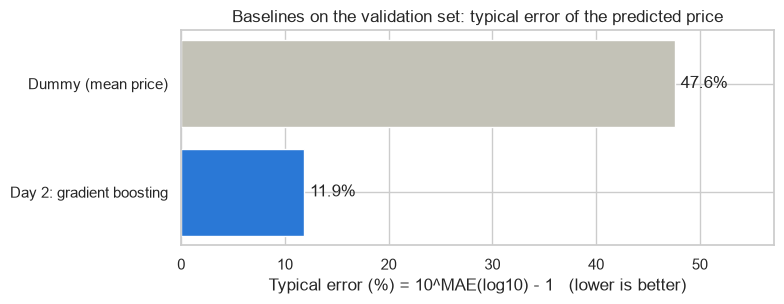

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
val_scores = baseline_results.xs("validation", level="evaluated on")["typical error (%)"]
bars = ax.barh(val_scores.index, val_scores.values, color=["#c3c2b7", "#2a78d6"])
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(title="Baselines on the validation set: typical error of the predicted price",
       xlabel="Typical error (%) = 10^MAE(log10) - 1   (lower is better)", xlim=(0, val_scores.max() * 1.2))
ax.invert_yaxis()
plt.tight_layout()
save_fig("00_baselines")
plt.show()

## Hand-off to the next sections

Everything the next sections need is ready. **Do not refit `preprocess` or change the splits**: the comparison with Day 2 depends on them.

- **`X_train_t`, `y_train_t`**: the training set as tensors (13,244 sales × `N_INPUTS` inputs; target `log10(price)` of shape (n, 1)). The network learns from these.
- **`X_val_t`, `y_val_t`**: the validation set (3,312 sales), to draw the training curves, stop early and compare settings.
- **`X_test_t`, `y_test_t`**: the test set (4,147 sales, the Day 2 test set). **Use it only once, in section 6.**
- **`X_train`, `X_val`, `X_test`** (and `y_...`): the same sets as pandas tables, in original units, for plots and for the application.
- **`N_INPUTS`**: the number of inputs of the network (82: 12 scaled numbers + 70 ZIP-code columns).
- **`preprocess`**: the fitted scaler + one-hot encoder. Save it as `models/scaler.joblib` in section 8.
- **`evaluate(y_true_log, y_pred_log)`**: returns R², MAE (log10), typical error (%) and MAE (USD), so every model is compared with the same metrics.
- **`baseline_results`** and **`day2_final`**: the baseline scores, and the Day 2 model fitted on the whole Day 2 training set, for the final comparison in section 6.
- **`DEVICE`**, **`RANDOM_STATE`** and **`save_fig(name, also_to_models=True)`**: the device, the seed, and a helper that saves a figure in `figures/` (and in `models/` for the model card).

Figures `00_target_distribution` and `00_baselines` are in `figures/`; the next sections can continue from `01_`.


# 3. Neural Network Model and Training

## 3.1 Model Architecture

We use a Multilayer Perceptron (MLP) to predict house prices using the same dataset as our Day 2 assignment.

The model receives 82 input features, including building characteristics and location information. It has two hidden layers with 64 and 32 neurons, followed by one output neuron that predicts the log10 of the house price.

We use ReLU activation functions in the hidden layers to help the network learn relationships between the features and prices.

The purpose is to find out whether a neural network can predict house prices more accurately than our previous gradient boosting model.


In [12]:

# 3.1 Build the neural network

from torchinfo import summary

# Set random seed for reproducibility
torch.manual_seed(RANDOM_STATE)

# Define the MLP architecture
model = nn.Sequential(
    nn.Linear(N_INPUTS, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(DEVICE)

# Display the model architecture
print(model)

# Show model summary
summary(model, input_size=(1, N_INPUTS), device=DEVICE)

# Count trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_parameters)


Sequential(
  (0): Linear(in_features=82, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Total trainable parameters: 7425



## 3.2 Training Setup

We train the neural network using PyTorch.

Mean Squared Error (MSE) is used as the loss function because our target is a continuous numerical value. The Adam optimizer updates the network weights to reduce prediction errors.

We use a learning rate of 0.001, a batch size of 64, and a maximum of 100 epochs.

The training dataset is used to update the model weights, while the validation dataset is used to check its performance on unseen data.

We also use early stopping to reduce overfitting. If the validation loss does not improve for 15 epochs, training stops and the best model weights are restored.

The test dataset is not used during training.


In [13]:

# 3.2 Train the neural network

from torch.utils.data import TensorDataset, DataLoader

# Create training batches
train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Define loss and optimizer
loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training settings
epochs = 100
patience = 15

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None
wait = 0

start_time = time.time()

# Training loop
for epoch in range(epochs):

    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = loss_fn(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(X_batch)

    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()

    with torch.no_grad():

        X_validation = X_val_t.to(DEVICE)
        y_validation = y_val_t.to(DEVICE)

        val_predictions = model(X_validation)

        val_loss = loss_fn(
            val_predictions,
            y_validation
        ).item()

    val_losses.append(val_loss)

    # Save the best weights in memory
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        wait = 0

    else:
        wait += 1

    # Show progress
    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {avg_train_loss:.5f} | "
            f"Validation Loss: {val_loss:.5f}"
        )

    # Early stopping
    if wait >= patience:

        print("Early stopping triggered.")
        break

# Restore best model weights
model.load_state_dict(best_model_state)

training_time = time.time() - start_time

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 5))
print("Training time:", round(training_time, 2), "seconds")
print("Device used:", DEVICE)


Epoch 1/100 | Train Loss: 6.96544 | Validation Loss: 0.29160


Epoch 10/100 | Train Loss: 0.00934 | Validation Loss: 0.00890


Epoch 20/100 | Train Loss: 0.00733 | Validation Loss: 0.00788


Epoch 30/100 | Train Loss: 0.00670 | Validation Loss: 0.00853


Epoch 40/100 | Train Loss: 0.00649 | Validation Loss: 0.00664


Epoch 50/100 | Train Loss: 0.00622 | Validation Loss: 0.00630


Epoch 60/100 | Train Loss: 0.00643 | Validation Loss: 0.00639


Early stopping triggered.

Training completed!
Best epoch: 46
Best validation loss: 0.00627
Training time: 14.93 seconds
Device used: mps



## 3.3 Training and Validation Loss

The graph below shows how the training and validation losses change during training.

Training loss measures how well the model learns from the training dataset. Validation loss measures how well the model performs on data that was not used to update its weights.

Lower loss means smaller prediction errors.

If both losses decrease, the model is learning. If training loss keeps decreasing but validation loss starts increasing, it may indicate overfitting.

We use the epoch with the lowest validation loss to select the best model weights.

Figure saved to ../figures/01_training_curves.png
Figure saved to ../models/01_training_curves.png


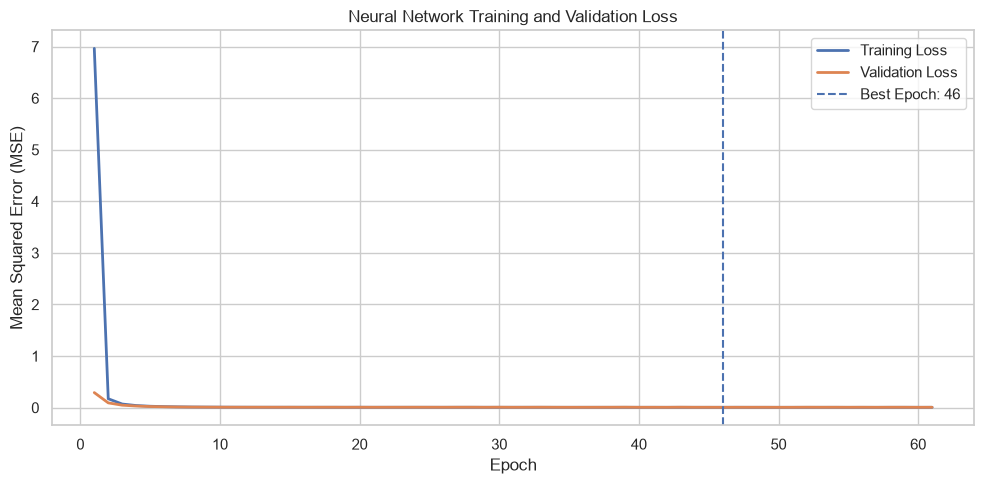

In [14]:

# 3.3 Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Neural Network Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the figure
save_fig("01_training_curves", also_to_models=True)

plt.show()

In [15]:

# 3.4 Check the trained model on validation data

model.eval()

with torch.no_grad():

    validation_predictions = model(
        X_val_t.to(DEVICE)
    ).cpu().numpy().flatten()

# Calculate validation metrics
network_val_results = evaluate(
    y_val.to_numpy(),
    validation_predictions
)

# Show results as a table
validation_table = pd.DataFrame(
    [network_val_results],
    index=["Neural Network"]
)

display(validation_table.round(3))

# Compare with Day 2 baseline on validation set
day2_val = baseline_results.loc[
    ("Day 2: gradient boosting", "validation"),
    "typical error (%)"
]

network_val = network_val_results["typical error (%)"]

print(f"Day 2 baseline typical error: {day2_val:.2f}%")
print(f"Neural network typical error: {network_val:.2f}%")

if network_val < day2_val:
    print("The neural network performs better on validation.")
else:
    print("The Day 2 baseline performs better on validation.")

,R² (log10),MAE (log10),typical error (%),MAE (USD)
Neural Network,0.856,0.058,14.307,"72,444.814"


Day 2 baseline typical error: 11.88%
Neural network typical error: 14.31%
The Day 2 baseline performs better on validation.



## 3.5 Training Summary

We built an MLP neural network using the same house-price data and preprocessing as the earlier sections.

The network has two hidden layers with 64 and 32 neurons and uses ReLU activation functions. We trained it using the Adam optimizer and Mean Squared Error loss.

We monitored both training and validation losses and used early stopping to keep the weights from the best validation epoch.

The results provide a starting point for the next section, where different network settings will be compared to see whether performance can be improved.

# 4. Diagnosis: looking inside the network

Section 3 trained the network and showed its learning curves. Here we open it up with the tools of class notebook 01 (`summary`, `parameter_table`, `draw_network`, `layer_outputs`), and then look at **where** it makes its errors on the validation set. The test set is still untouched.

The three helper functions below are copied from class notebook 01 (section 2, "Looking inside a network").

In [16]:
def parameter_table(model):
    # One row per weight matrix and bias vector: its shape, how many numbers it holds and their spread
    rows = []
    for name, p in model.named_parameters():
        values = p.detach().cpu().numpy()
        rows.append({"parameter": name, "shape": tuple(values.shape), "count": values.size,
                     "mean": values.mean(), "std": values.std(), "min": values.min(), "max": values.max()})
    return pd.DataFrame(rows).set_index("parameter")


def layer_outputs(model, x):
    # Pass x through a Sequential model one layer at a time and keep what comes out of each layer
    outputs = []
    with torch.no_grad():
        for name, layer in model.named_children():
            x = layer(x)
            outputs.append((f"{name}: {layer.__class__.__name__}", x.cpu()))
    return outputs


def draw_network(model, input_names=None, output_names=None, max_neurons=12, weight_scale=None, title=None, ax=None):
    # Draw the Linear (dense) layers of a model: circles are neurons, lines are weights.
    # Blue = positive weight, red = negative; the thicker and darker the line, the larger the weight.
    # weight_scale = the weight drawn at full strength (default: the largest one in each layer).
    # Wide layers only show their first `max_neurons` neurons.
    layers = list(model) if isinstance(model, nn.Sequential) else [model]
    linears = [layer for layer in layers if isinstance(layer, nn.Linear)]

    labels = []
    for layer in layers:
        if isinstance(layer, nn.Linear):
            labels.append(f"Linear {layer.in_features}→{layer.out_features}")
        elif not isinstance(layer, nn.Dropout) and labels:
            labels[-1] += f"\n+ {layer.__class__.__name__}"

    sizes = [linears[0].in_features] + [layer.out_features for layer in linears]
    shown = [min(n, max_neurons) for n in sizes]
    spacing = [min(2 / max(n - 1, 1), 0.6) for n in shown]
    ys = [(np.arange(n) - (n - 1) / 2) * -gap for n, gap in zip(shown, spacing)]

    if ax is None:
        fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 6))

    for l, layer in enumerate(linears):
        W = layer.weight.detach().cpu().numpy()[:shown[l + 1], :shown[l]]
        scale = weight_scale or np.abs(W).max()
        for j, y_out in enumerate(ys[l + 1]):
            for i, y_in in enumerate(ys[l]):
                strength = min(abs(W[j, i]) / scale, 1)
                ax.plot([l, l + 1], [y_in, y_out], color="tab:blue" if W[j, i] > 0 else "tab:red",
                        lw=0.3 + 3 * strength, alpha=0.15 + 0.75 * strength, zorder=1)
                if W.size <= 12:
                    ax.text(l + 0.3, y_in + 0.3 * (y_out - y_in), f"{W[j, i]:+.2f}", fontsize=9,
                            ha="center", va="bottom", color="dimgrey")

    circle_size = np.clip(2500 / max(shown), 60, 700)
    for l, (n, y) in enumerate(zip(sizes, ys)):
        ax.scatter(np.full(len(y), l), y, s=circle_size, color="lightgrey" if l == 0 else "white",
                   edgecolors="black", zorder=2)
        if n > len(y):
            ax.text(l, y.min() - 0.12, f"+ {n - len(y)} more", ha="center", va="top", fontsize=9)
        ax.text(l, -1.3, "Input" if l == 0 else labels[l - 1], ha="center", va="top", fontsize=10)
    for name, y in zip(input_names or [], ys[0]):
        ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    for name, y in zip(output_names or [], ys[-1]):
        ax.text(len(sizes) - 0.85, y, name, ha="left", va="center", fontsize=9)

    n_params = sum(p.numel() for p in model.parameters())
    ax.set_title(title or f"{n_params:,} parameters")
    ax.set_xlim(-1, len(sizes) - 0.2)
    ax.set_ylim(-1.7, 1.2)
    ax.axis("off")
    return ax

## 4.1 The architecture, layer by layer

`summary` shows what goes in and out of every layer for a batch of 32 houses, and where the parameters are.

In [17]:
print(summary(model, input_data=X_train_t[:32].to(DEVICE), col_names=["input_size", "output_size", "num_params"],
              device=DEVICE, verbose=0))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [32, 82]                  [32, 1]                   --
├─Linear: 1-1                            [32, 82]                  [32, 64]                  5,312
├─ReLU: 1-2                              [32, 64]                  [32, 64]                  --
├─Linear: 1-3                            [32, 64]                  [32, 32]                  2,080
├─ReLU: 1-4                              [32, 32]                  [32, 32]                  --
├─Linear: 1-5                            [32, 32]                  [32, 1]                   33
Total params: 7,425
Trainable params: 7,425
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.24
Input size (MB): 0.01
Forward/backward pass size (MB): 0.02
Params size (MB): 0.03
Estimated Total Size (MB): 0.07


**Reading.** The network has **7,425 parameters**, and 5,312 of them (72%) sit in the first layer, because each of the 64 neurons has a weight for each of the 82 inputs (12 numbers + 70 ZIP codes). This is a small model for 13,244 training houses (about 1.8 houses per parameter).

## 4.2 The weights before and after training

Section 3 built the network right after `torch.manual_seed(RANDOM_STATE)`. Building it again with the same seed gives back **exactly the random weights it started from**, so we can compare the network before and after training.

In [18]:
def make_section3_network():
    # The architecture of section 3: 82 inputs -> 64 -> 32 -> 1 output, ReLU in between
    return nn.Sequential(nn.Linear(N_INPUTS, 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(),
                         nn.Linear(32, 1))


torch.manual_seed(RANDOM_STATE)
model_untrained = make_section3_network().to(DEVICE)    # = the starting point of section 3

weights = pd.concat({"before training": parameter_table(model_untrained)[["std", "min", "max"]],
                     "after training": parameter_table(model)[["std", "min", "max"]]}, axis=1)
weights.insert(0, "count", parameter_table(model)["count"])
weights

count before training              after training             
                            std    min   max            std    min   max
parameter                                                               
0.weight   5248           0.064 -0.110 0.110          0.098 -0.451 0.383
0.bias       64           0.061 -0.107 0.105          0.094 -0.011 0.362
2.weight   2048           0.073 -0.125 0.125          0.091 -0.283 0.422
2.bias       32           0.071 -0.122 0.115          0.122 -0.243 0.288
4.weight     32           0.103 -0.172 0.170          0.157 -0.458 0.249
4.bias        1           0.000  0.106 0.106          0.000  0.217 0.217

Figure saved to ../figures/02_network_before_after.png


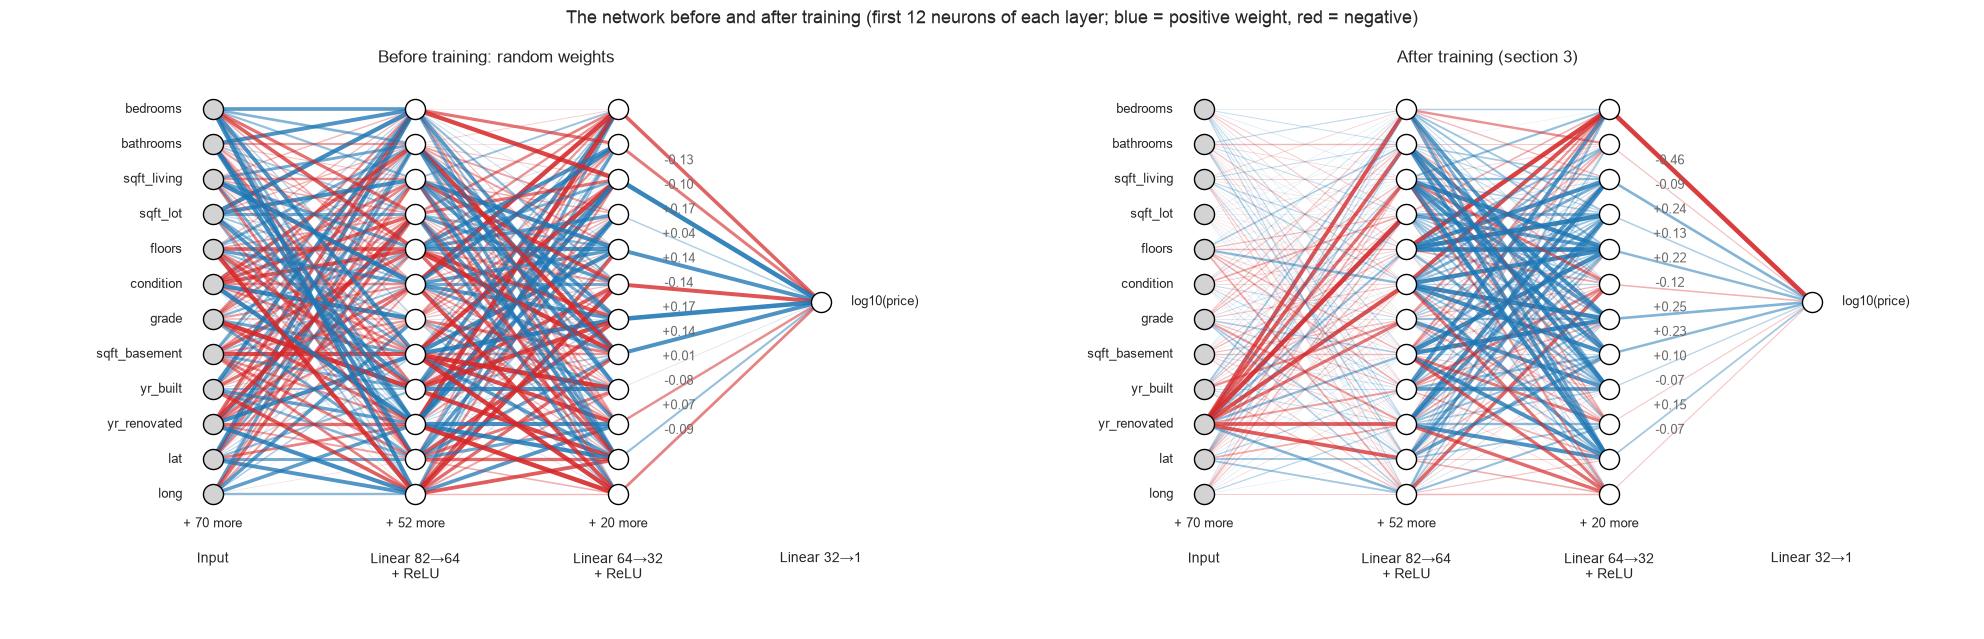

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6.5))
draw_network(model_untrained, input_names=NUMERIC_COLUMNS, output_names=["log10(price)"], ax=axes[0],
             title="Before training: random weights")
draw_network(model, input_names=NUMERIC_COLUMNS, output_names=["log10(price)"], ax=axes[1],
             title="After training (section 3)")
fig.suptitle("The network before and after training (first 12 neurons of each layer; blue = positive weight, red = negative)",
             fontsize=13)
plt.tight_layout()
save_fig("02_network_before_after")
plt.show()

**Reading.** Before training, the weights are small random numbers spread evenly between about -0.11 and +0.11 (the PyTorch default for 82 inputs), and every line in the left drawing looks alike. After training they are **spread out and structured**: some connections became strong (up to ±0.45), most of the others faded. A few inputs, such as `yr_renovated`, now have several strong (red, negative) connections while many others faded, and one neuron of the second layer got a large negative weight (-0.46) towards the output. The output bias grew from 0.11 to only 0.22, although the average target is 5.68: the network had to build the whole price level out of its hidden neurons. We come back to this in 4.4.

## 4.3 Following one house through the network

We take the validation house whose price is closest to the median and pass it through the network one layer at a time with `layer_outputs`. After each ReLU, a neuron is either **active** (positive value, it passes information on) or **silent** (exactly 0).

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_basement,yr_built,yr_renovated,lat,long,zipcode
14248,3,1.750,2580,11000,1.000,4,7,1290,1951,0,47.565,-122.181,98006


Figure saved to ../figures/03_one_house_through_network.png


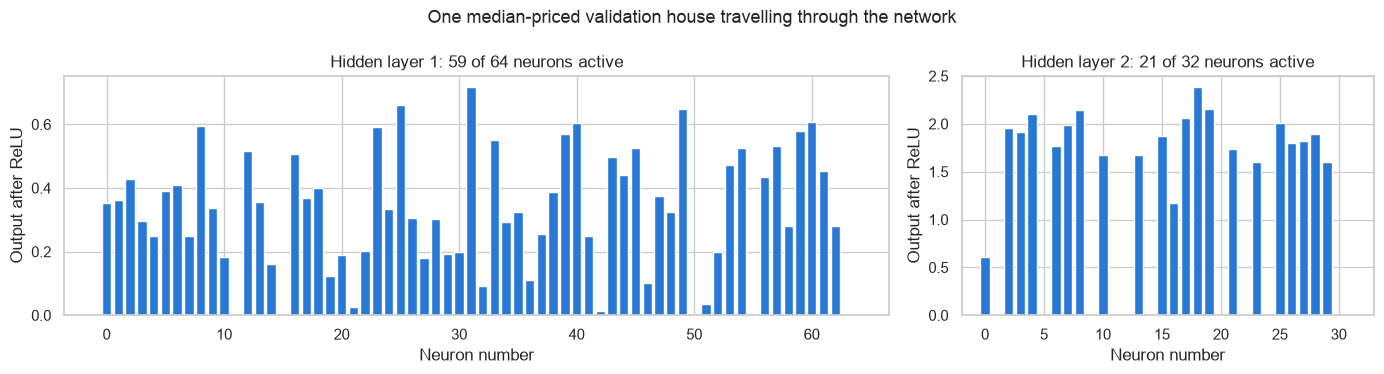

Output neuron: log10(price) = 5.740 -> predicted 549,672 USD, actual 459,900 USD (+19.5%)


In [20]:
house_pos = int(np.argmin(np.abs(y_val.to_numpy() - y_val.median())))
display(X_val.iloc[[house_pos]])

steps = layer_outputs(model, X_val_t[house_pos:house_pos + 1].to(DEVICE))
relu_steps = [(name, out.numpy().ravel()) for name, out in steps if "ReLU" in name]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for ax, (name, values), n_layer in zip(axes, relu_steps, [1, 2]):
    ax.bar(range(len(values)), values, color=np.where(values > 0, "#2a78d6", "#c3c2b7"))
    ax.set(title=f"Hidden layer {n_layer}: {(values > 0).sum()} of {len(values)} neurons active",
           xlabel="Neuron number", ylabel="Output after ReLU")
plt.suptitle("One median-priced validation house travelling through the network", fontsize=13)
plt.tight_layout()
save_fig("03_one_house_through_network")
plt.show()

predicted_log = steps[-1][1].item()
actual = 10 ** y_val.iloc[house_pos]
print(f"Output neuron: log10(price) = {predicted_log:.3f} -> predicted {10 ** predicted_log:,.0f} USD, "
      f"actual {actual:,.0f} USD ({(10 ** predicted_log / actual - 1) * 100:+.1f}%)")

**Reading.** The median house of the validation set (1951, 2,580 sqft, grade 7, ZIP 98006) switches on 59 of the 64 neurons of the first layer, but only **21 of the 32** of the second. The network predicts about 550,000 USD for a house sold at 459,900 USD: **almost 20% too high**, more than its typical error. One house is only an example, but the silent second layer is a clue, which the next cell checks on all validation houses.

## 4.4 Dead neurons: damage done in the first epoch

A ReLU neuron that outputs 0 for **every** house is "dead": it never passes information on and receives no gradient, so training can never bring it back. We count them over the 3,312 validation houses, before and after training.

In [21]:
def dead_neurons(net, X_t):
    # Per hidden layer: how many ReLU neurons output 0 for every house in X_t
    counts, layer = {}, 0
    for name, out in layer_outputs(net, X_t.to(next(net.parameters()).device)):
        if "ReLU" in name:
            layer += 1
            counts[f"hidden layer {layer}"] = f"{int(((out > 0).sum(dim=0) == 0).sum())} of {out.shape[1]}"
    return counts


pd.DataFrame({"dead before training": dead_neurons(model_untrained, X_val_t),
              "dead after training": dead_neurons(model, X_val_t)})

,dead before training,dead after training
hidden layer 1,0 of 64,0 of 64
hidden layer 2,0 of 32,10 of 32


**Reading.** Before training no neuron is dead. After training, **10 of the 32 neurons of the second hidden layer are dead**: they output 0 for all 3,312 validation houses, so the network really works with 22 neurons there. Section 3 shows why: in epoch 1 the training loss was 6.97, because the network starts by predicting about 0 for a target of about 5.7. The first gradient steps are therefore very large, and they push some neurons so far into the negative zone of the ReLU that they can never come back. (In a separate check on the CPU, 7 of these neurons are already dead after the **first epoch** and the number then barely changes.) This gives us the first experiment of section 5: start the output neuron at the average price, so that the first errors are small.

## 4.5 Where does the network make its errors?

We compare the errors of the section 3 network on the validation set with those of the Day 2 model (trained on the same training set), split into five price bands of equal size.

Figure saved to ../figures/04_validation_errors.png


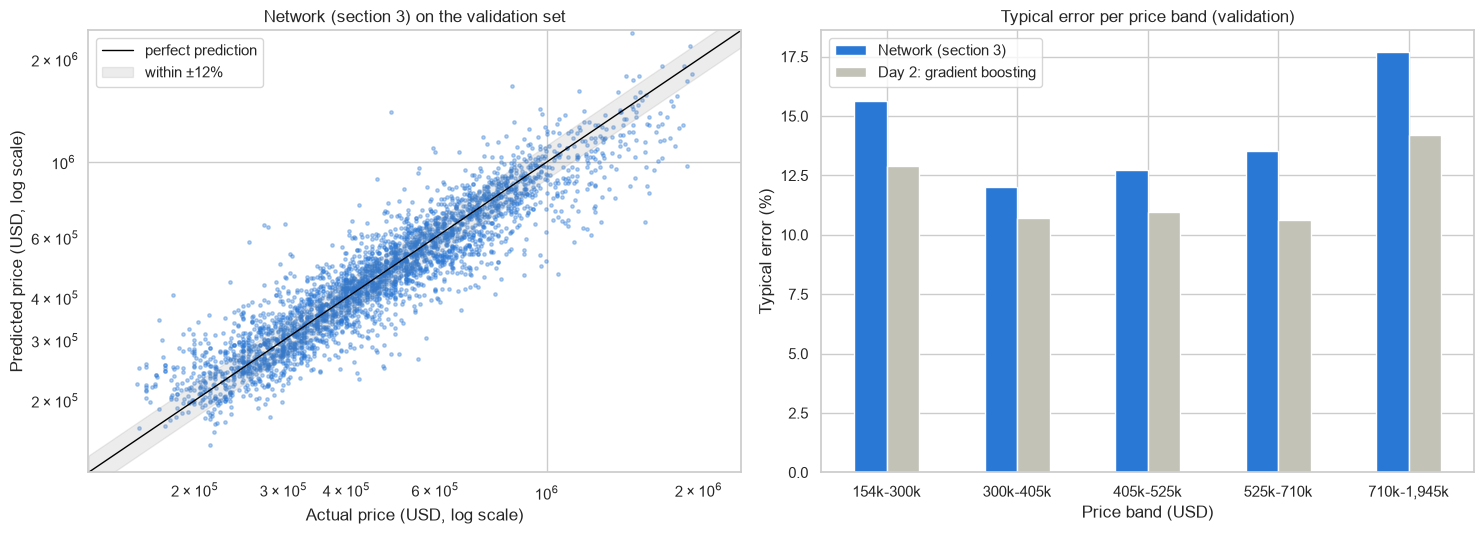

,Network (section 3),Day 2: gradient boosting
154k-300k,15.700,12.900
300k-405k,12.000,10.700
405k-525k,12.700,11.000
525k-710k,13.500,10.600
"710k-1,945k",17.700,14.200


In [22]:
day2_val_model = day2_model().fit(X_train, y_train)          # the Day 2 model, trained on the training set only
day2_val_pred = day2_val_model.predict(X_val)


def errors_by_band(y_true_log, predictions, bands):
    # Typical error (%) per price band, for several models: 10^mean(|log error|) - 1
    table = {}
    for name, pred in predictions.items():
        abs_log_error = pd.Series(np.abs(np.asarray(pred) - np.asarray(y_true_log)), index=bands.index)
        table[name] = (10 ** abs_log_error.groupby(bands, observed=True).mean() - 1) * 100
    return pd.DataFrame(table)


def price_bands(prices):
    # Five price bands with 20% of the houses each, labelled like "250k-340k"
    edges = np.quantile(prices, [0, 0.2, 0.4, 0.6, 0.8, 1])
    labels = [f"{lo / 1000:,.0f}k-{hi / 1000:,.0f}k" for lo, hi in zip(edges[:-1], edges[1:])]
    return pd.qcut(pd.Series(np.asarray(prices)), 5, labels=labels)


val_price = 10 ** y_val.reset_index(drop=True)
val_bands = price_bands(val_price)
val_by_band = errors_by_band(y_val, {"Network (section 3)": validation_predictions,
                                     "Day 2: gradient boosting": day2_val_pred}, val_bands)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(val_price, 10 ** validation_predictions, s=6, alpha=0.35, color="#2a78d6")
lims = [val_price.min() * 0.8, val_price.max() * 1.25]
ax.plot(lims, lims, color="black", lw=1, label="perfect prediction")
ax.fill_between(lims, [l / 1.12 for l in lims], [l * 1.12 for l in lims], color="grey", alpha=0.15,
                label="within ±12%")
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, title="Network (section 3) on the validation set",
       xlabel="Actual price (USD, log scale)", ylabel="Predicted price (USD, log scale)")
ax.legend()
val_by_band.plot.bar(ax=axes[1], color=["#2a78d6", "#c3c2b7"], rot=0)
axes[1].set(title="Typical error per price band (validation)", xlabel="Price band (USD)",
            ylabel="Typical error (%)")
plt.tight_layout()
save_fig("04_validation_errors")
plt.show()
val_by_band.round(1)

In [23]:
# The five validation houses with the largest error, to see what kind of house the network gets wrong
worst = X_val.reset_index(drop=True).assign(
    price=val_price.round(-3), predicted=(10 ** validation_predictions).round(-3),
    error_pct=((10 ** validation_predictions / val_price - 1) * 100).round(1))
worst.reindex(worst["error_pct"].abs().sort_values(ascending=False).index).head(5)[
    ["price", "predicted", "error_pct", "sqft_living", "sqft_lot", "grade", "condition", "yr_built", "zipcode"]]

,price,predicted,error_pct,sqft_living,sqft_lot,grade,condition,yr_built,zipcode
3272,"490,000.000","1,402,000.000",186.200,4460,2975,10,3,2015,98119
46,"275,000.000","654,000.000",137.700,3030,45004,9,3,1987,98077
967,"280,000.000","647,000.000",131.000,2280,37500,7,3,1932,98136
2114,"257,000.000","583,000.000",126.700,2930,10148,9,3,2002,98059
839,"181,000.000","407,000.000",124.800,1310,4000,7,3,1942,98144


**Reading.**

- **The errors follow the diagonal without a clear bias** in the middle of the market, but the cloud is wider than the ±12% band: the network is typically 14.3% off, against 11.9% for the Day 2 model on the same validation houses.
- **The network is worse than the Day 2 model in every price band**, and the gap is largest at both ends: **cheap houses** under 300,000 USD (15.7% against 12.9%) and **expensive houses** over 710,000 USD (17.7% against 14.2%). Few training examples lie at the ends, and a single smooth function struggles more with them than trees, which can cut the data into small groups.
- **The worst errors are over-estimates of houses that sold far below what their description suggests:** a new (2015) grade-10 house of 4,460 sqft in ZIP 98119 sold for 490,000 USD and predicted at 1.4 million, or older houses on very large lots (37,500 and 45,000 sqft) predicted at more than twice their price. These are probably special sales (an unfinished building, land with constraints) that our 13 columns cannot describe: no model on these inputs could get them right.

# 5. Tuning and regularisation: experiments

Section 4 found two problems: the network loses neurons in the first epoch, and it stops improving after a few dozen epochs while it is still about 2.5 points worse than the Day 2 model. Here we try to fix them with **controlled experiments**.

**How we run the experiments:**

- **One change at a time.** Each experiment changes **one** setting relative to a reference, so the difference in the table can be attributed to that change. We work in three rounds: round 1 starts from the section 3 settings, round 2 starts from the winner of round 1, and round 3 combines the changes that helped in round 2.
- **Three seeds per setting.** One training run can be lucky or unlucky (random starting weights, random batch order). Each setting is trained with seeds 42, 7 and 2026, and we report the **mean and the spread** of the validation error. A difference smaller than the spread is not a real difference.
- **Selection on our metric.** Early stopping keeps the epoch with the lowest **validation typical error** (the metric of the use case), not the lowest validation MSE.
- **Validation only.** Every decision in this section uses the validation set. The test set is used once, in section 6.
- **On the CPU.** For a network this small, the CPU is faster than a GPU (moving tiny batches to the GPU costs more than the computation), and it gives the same numbers on every laptop.

## 5.1 A configurable network and training loop

In [24]:
EXP_DEVICE = "cpu"
SEEDS = [42, 7, 2026]
LOSSES = {"mse": nn.MSELoss(), "huber": nn.HuberLoss(delta=0.05), "l1": nn.L1Loss()}

# The settings of section 3: the reference of round 1
SECTION3_SETTINGS = dict(hidden=(64, 32), dropout=0.0, bias_init=False, loss="mse", lr=1e-3, weight_decay=0.0,
                         batch_size=64, epochs=100, patience=15, lr_schedule=False)


def make_mlp(hidden=(64, 32), dropout=0.0, bias_init=False):
    # MLP: N_INPUTS -> hidden layers (ReLU, optional dropout) -> 1 output = log10(price)
    layers, n_in = [], N_INPUTS
    for n_out in hidden:
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        n_in = n_out
    layers.append(nn.Linear(n_in, 1))
    net = nn.Sequential(*layers)
    if bias_init:
        # Start the output at the average log10(price) of the training set instead of at ~0
        with torch.no_grad():
            net[-1].bias.fill_(y_train_t.mean().item())
    return net


def typical_error(net, X_t, y_t):
    # Typical error in % (10^MAE(log10) - 1) of the network on one set
    net.eval()
    with torch.no_grad():
        mae_log = (net(X_t.to(EXP_DEVICE)).cpu() - y_t).abs().mean().item()
    return (10 ** mae_log - 1) * 100


def train_mlp(seed=RANDOM_STATE, hidden=(64, 32), dropout=0.0, bias_init=False, loss="mse", lr=1e-3,
              weight_decay=0.0, batch_size=64, epochs=100, patience=15, lr_schedule=False):
    # Train with Adam; after each epoch record the training and validation typical error.
    # Keep the weights of the epoch with the lowest validation error; stop after `patience` epochs without progress.
    # lr_schedule=True halves the learning rate when the validation error has not improved for 5 epochs.
    torch.manual_seed(seed)
    net = make_mlp(hidden, dropout, bias_init).to(EXP_DEVICE)
    loss_fn = LOSSES[loss]
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=5) if lr_schedule else None
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    history, best_error, best_state, waited = [], np.inf, None, 0
    for epoch in range(1, epochs + 1):
        net.train()
        for xb, yb in loader:
            xb, yb = xb.to(EXP_DEVICE), yb.to(EXP_DEVICE)
            optimizer.zero_grad()
            loss_fn(net(xb), yb).backward()
            optimizer.step()
        val_error = typical_error(net, X_val_t, y_val_t)
        history.append({"epoch": epoch, "train error (%)": typical_error(net, X_train_t, y_train_t),
                        "validation error (%)": val_error, "learning rate": optimizer.param_groups[0]["lr"]})
        if scheduler is not None:
            scheduler.step(val_error)
        if val_error < best_error:
            best_error, waited = val_error, 0
            best_state = copy.deepcopy(net.state_dict())
        else:
            waited += 1
            if waited >= patience:
                break
    net.load_state_dict(best_state)
    return net, pd.DataFrame(history).set_index("epoch")


def run_round(base, changes):
    # Train every variant (base settings + one change) with the three seeds; one row per variant
    rows = {}
    for name, change in changes.items():
        start = time.time()
        errors, best_epochs = [], []
        for seed in SEEDS:
            _, history = train_mlp(seed=seed, **{**base, **change})
            errors.append(history["validation error (%)"].min())
            best_epochs.append(history["validation error (%)"].idxmin())
        rows[name] = {"validation error (%)": np.mean(errors), "± (spread over 3 seeds)": np.std(errors),
                      "best epoch (mean)": np.mean(best_epochs), "seconds": time.time() - start}
        print(f"{name:45s} {np.mean(errors):6.2f}% ± {np.std(errors):.2f}")
    return pd.DataFrame(rows).T


experiment_settings = {}     # name -> full settings, to retrieve the winner at the end


def register(base, changes, prefix):
    for name, change in changes.items():
        experiment_settings[f"{prefix} {name}"] = {**base, **change}
    return {f"{prefix} {name}": change for name, change in changes.items()}

## 5.2 Round 1: one change at a time from the section 3 settings

- **Output bias at the mean price:** our own idea, from section 4.4. The network starts by predicting about 0 while the target is about 5.7, so the first gradients are huge (training loss 6.97 in epoch 1, against 0.006 at the end). Starting the output neuron at the average `log10(price)` removes that first shock.
- **Loss function:** Huber (squared error for small errors, absolute error for large ones, so outliers pull less) and L1 (directly the MAE that we report).
- **Size:** wider (128-64), deeper (256-128-64) and smaller (32-16).
- **Regularisation** (class notebook 01, section 5): dropout 0.1 and weight decay 1e-4.
- **Optimisation:** a larger learning rate (3e-3), a learning rate halved when progress stops, and larger batches (256).

In [25]:
round1 = run_round(SECTION3_SETTINGS, register(SECTION3_SETTINGS, {
    "section 3 settings (reference)": {},
    "output bias starts at the mean price": {"bias_init": True},
    "Huber loss": {"loss": "huber"},
    "L1 loss": {"loss": "l1"},
    "wider: 128-64": {"hidden": (128, 64)},
    "deeper: 256-128-64": {"hidden": (256, 128, 64)},
    "smaller: 32-16": {"hidden": (32, 16)},
    "dropout 0.1": {"dropout": 0.1},
    "weight decay 1e-4": {"weight_decay": 1e-4},
    "learning rate 3e-3": {"lr": 3e-3},
    "learning rate halved on plateau": {"lr_schedule": True, "epochs": 200, "patience": 20},
    "batch size 256": {"batch_size": 256},
}, "R1"))
round1.round(2)

R1 section 3 settings (reference)              14.39% ± 0.07


R1 output bias starts at the mean price        12.73% ± 0.04


R1 Huber loss                                  13.83% ± 0.05


R1 L1 loss                                     14.37% ± 0.44


R1 wider: 128-64                               14.35% ± 0.29


R1 deeper: 256-128-64                          15.70% ± 0.22


... (3 outputs left out)

R1 learning rate 3e-3                          15.31% ± 0.29


R1 learning rate halved on plateau             13.35% ± 0.17


R1 batch size 256                              14.04% ± 0.28


,validation error (%),± (spread over 3 seeds),best epoch (mean),seconds
R1 section 3 settings (reference),14.390,0.070,39.000,8.080
R1 output bias starts at the mean price,12.730,0.040,14.330,4.400
R1 Huber loss,13.830,0.050,39.670,8.190
R1 L1 loss,14.370,0.440,24.330,6.010
R1 wider: 128-64,14.350,0.290,52.330,11.830
R1 deeper: 256-128-64,15.700,0.220,17.330,8.170
R1 smaller: 32-16,13.860,0.140,70.000,12.440
R1 dropout 0.1,12.940,0.080,97.670,16.880
R1 weight decay 1e-4,13.770,0.280,56.670,11.140
R1 learning rate 3e-3,15.310,0.290,20.670,5.400


**Reading.** Each row changes one thing relative to the first row (14.4% ± 0.1):

- **Starting the output bias at the mean price is by far the best change: 14.4% → 12.7%.** It costs nothing (one line of code), it is the most stable of all (± 0.04), and the best epoch comes much earlier (about 14 instead of 39). This confirms the diagnosis of section 4.4: the shock of the first epoch damaged the network.
- **Dropout 0.1 (12.9%) and halving the learning rate on a plateau (13.4%) also help**, but they need many more epochs (dropout still improves at epoch 100, the limit).
- **Bigger is worse**: the deeper network (256-128-64, 43,000 parameters) reaches 15.7%, and a larger learning rate (3e-3) 15.3%. With 13,000 houses, more capacity mostly means more noise.
- **L1 loss** gives the same mean as MSE but with the largest spread (± 0.44): it is the least reliable change.

## 5.3 Round 2: one change at a time from the winner of round 1

The new reference starts the output bias at the mean price. We also give every variant more room (up to 300 epochs, patience 30), because regularised networks learn more slowly; the first row checks that this extra room alone changes nothing.

In [26]:
ROUND2_BASE = {**SECTION3_SETTINGS, "bias_init": True, "epochs": 300, "patience": 30}

round2 = run_round(ROUND2_BASE, register(ROUND2_BASE, {
    "bias at mean (reference)": {},
    "weight decay 1e-4": {"weight_decay": 1e-4},
    "weight decay 3e-4": {"weight_decay": 3e-4},
    "weight decay 1e-3": {"weight_decay": 1e-3},
    "Huber loss": {"loss": "huber"},
    "L1 loss": {"loss": "l1"},
    "dropout 0.1": {"dropout": 0.1},
    "learning rate halved on plateau": {"lr_schedule": True},
    "learning rate 3e-4": {"lr": 3e-4},
    "wider: 128-64": {"hidden": (128, 64)},
}, "R2"))
round2.round(2)

R2 bias at mean (reference)                    12.73% ± 0.04


R2 weight decay 1e-4                           12.43% ± 0.05


R2 weight decay 3e-4                           12.49% ± 0.04


R2 weight decay 1e-3                           12.99% ± 0.01


R2 Huber loss                                  12.58% ± 0.03


R2 L1 loss                                     12.63% ± 0.06


R2 dropout 0.1                                 12.67% ± 0.08


R2 learning rate halved on plateau             12.69% ± 0.01


R2 learning rate 3e-4                          12.70% ± 0.04


R2 wider: 128-64                               12.79% ± 0.09


,validation error (%),± (spread over 3 seeds),best epoch (mean),seconds
R2 bias at mean (reference),12.730,0.040,14.330,6.790
R2 weight decay 1e-4,12.430,0.050,32.000,9.680
R2 weight decay 3e-4,12.490,0.040,50.330,14.130
R2 weight decay 1e-3,12.990,0.010,51.330,12.850
R2 Huber loss,12.580,0.030,13.000,6.490
R2 L1 loss,12.630,0.060,20.330,7.830
R2 dropout 0.1,12.670,0.080,29.670,10.050
R2 learning rate halved on plateau,12.690,0.010,16.670,7.060
R2 learning rate 3e-4,12.700,0.040,30.330,9.170
R2 wider: 128-64,12.790,0.090,11.000,7.330


**Reading.** Starting from 12.7%, the differences are much smaller than in round 1, so the spread matters:

- **Weight decay 1e-4 is the best single change (12.4% ± 0.05)**, followed by 3e-4 (12.5%). With 1e-3 the penalty is too strong and the error goes up (13.0%): the network is held back from learning.
- **Huber (12.6%) and L1 (12.6%) help a little** now that the start is stable: their advantage over MSE is about 0.1-0.15 points, about two to three times the spread.
- Dropout, halving the learning rate, a lower learning rate and a wider network change less than 0.1 point: **not a real difference**.
- More room (300 epochs, patience 30) changes nothing for the reference: the best epoch is still around 14.

## 5.4 Round 3: combining what helped

We combine weight decay 1e-4 (the best single change of round 2) with the other changes that helped, first two at a time, then three.

In [27]:
ROUND3_BASE = {**ROUND2_BASE, "weight_decay": 1e-4}

round3 = run_round(ROUND3_BASE, register(ROUND3_BASE, {
    "weight decay 1e-4 (reference)": {},
    "+ Huber loss": {"loss": "huber"},
    "+ learning rate halved on plateau": {"lr_schedule": True},
    "+ dropout 0.1": {"dropout": 0.1},
    "+ Huber loss + learning rate halved on plateau": {"loss": "huber", "lr_schedule": True},
}, "R3"))
round3.round(2)

R3 weight decay 1e-4 (reference)               12.43% ± 0.05


R3 + Huber loss                                12.51% ± 0.05


R3 + learning rate halved on plateau           12.34% ± 0.04


R3 + dropout 0.1                               12.46% ± 0.02


R3 + Huber loss + learning rate halved on plateau  12.30% ± 0.01


,validation error (%),± (spread over 3 seeds),best epoch (mean),seconds
R3 weight decay 1e-4 (reference),12.430,0.050,32.000,9.610
R3 + Huber loss,12.510,0.050,53.000,12.860
R3 + learning rate halved on plateau,12.340,0.040,49.330,12.340
R3 + dropout 0.1,12.460,0.020,51.670,14.180
R3 + Huber loss + learning rate halved on plateau,12.300,0.010,84.330,17.800


Figure saved to ../figures/05_experiments.png


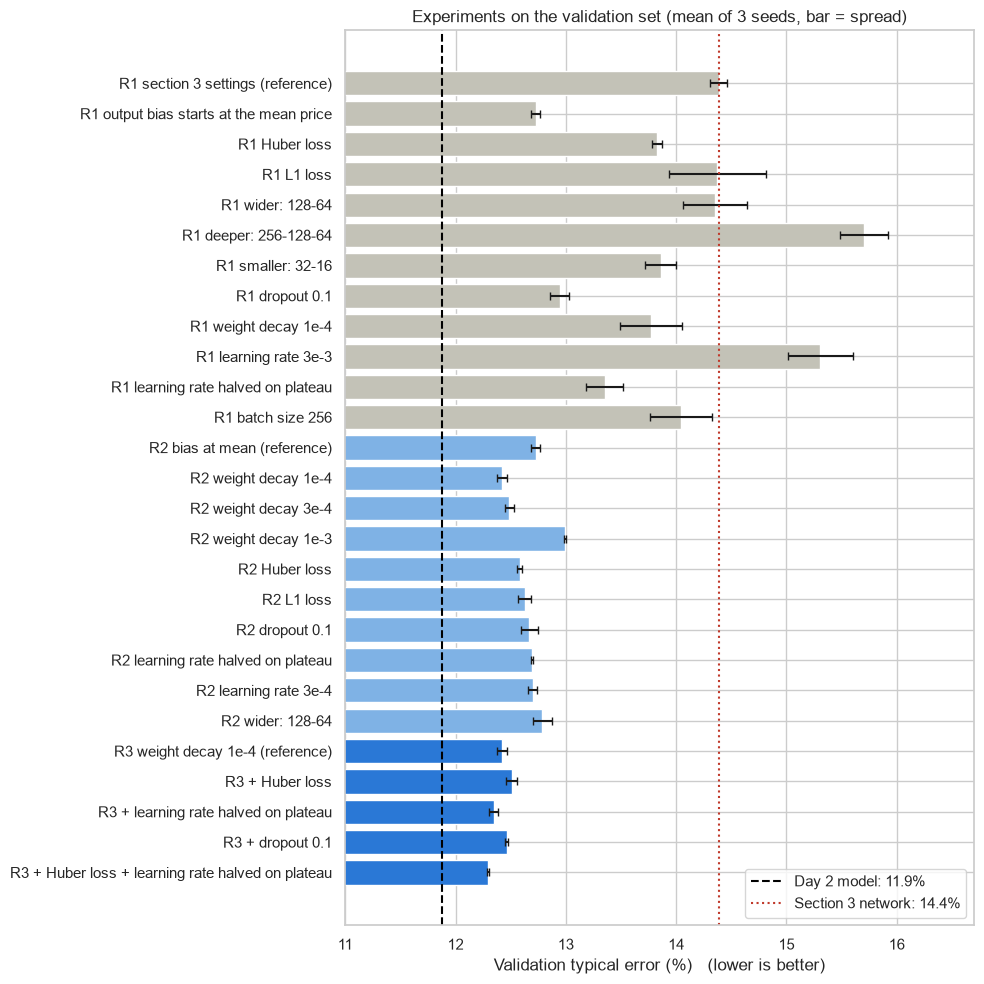

In [28]:
experiments = pd.concat([round1, round2, round3])
day2_val_error = baseline_results.loc[("Day 2: gradient boosting", "validation"), "typical error (%)"]
round_colors = {"R1": "#c3c2b7", "R2": "#7fb2e5", "R3": "#2a78d6"}

fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(experiments.index, experiments["validation error (%)"], xerr=experiments["± (spread over 3 seeds)"],
        color=[round_colors[name[:2]] for name in experiments.index], capsize=3)
ax.axvline(day2_val_error, color="black", ls="--", lw=1.5, label=f"Day 2 model: {day2_val_error:.1f}%")
ax.axvline(round1.iloc[0, 0], color="#c0392b", ls=":", lw=1.5, label=f"Section 3 network: {round1.iloc[0, 0]:.1f}%")
ax.set(title="Experiments on the validation set (mean of 3 seeds, bar = spread)",
       xlabel="Validation typical error (%)   (lower is better)", xlim=(11, experiments["validation error (%)"].max() + 1))
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("05_experiments")
plt.show()

**Reading.** Combining weight decay with **Huber loss and halving the learning rate** gives the best setting: **12.30% ± 0.01**, the lowest error and also the most stable over the three seeds. Halving the learning rate lets the network make smaller and smaller steps once it is close to a good solution, which is why this combination keeps improving until epoch 80 or so.

**The figure sums up the whole section:** the experiments brought the network from **14.4% to 12.3%**, a gain of 2.1 points, three-quarters of which comes from one line (the output bias). But **no setting crosses the dashed line of the Day 2 model (11.9%)**. On this tabular data, gradient boosting remains hard to beat.

## 5.5 The final settings

We keep the setting with the lowest mean validation error over all rounds and train it once more with our usual seed (42). This is the model that goes to the test set, to Hugging Face and to the application.

In [29]:
best_name = experiments["validation error (%)"].idxmin()
FINAL_SETTINGS = experiment_settings[best_name]
print(f"Selected: {best_name}")
print(FINAL_SETTINGS)

final_model, final_history = train_mlp(seed=RANDOM_STATE, **FINAL_SETTINGS)
_, section3_history = train_mlp(seed=RANDOM_STATE, **SECTION3_SETTINGS)    # the section 3 settings, same seed, same loop

print(f"\nFinal network: {sum(p.numel() for p in final_model.parameters()):,} parameters, "
      f"best epoch {final_history['validation error (%)'].idxmin()} of {len(final_history)}, "
      f"validation typical error {final_history['validation error (%)'].min():.2f}%")
print(final_model)

Selected: R3 + Huber loss + learning rate halved on plateau
{'hidden': (64, 32), 'dropout': 0.0, 'bias_init': True, 'loss': 'huber', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'epochs': 300, 'patience': 30, 'lr_schedule': True}



Final network: 7,425 parameters, best epoch 75 of 105, validation typical error 12.29%
Sequential(
  (0): Linear(in_features=82, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


Figure saved to ../figures/06_training_curves_final.png


Figure saved to ../models/06_training_curves_final.png


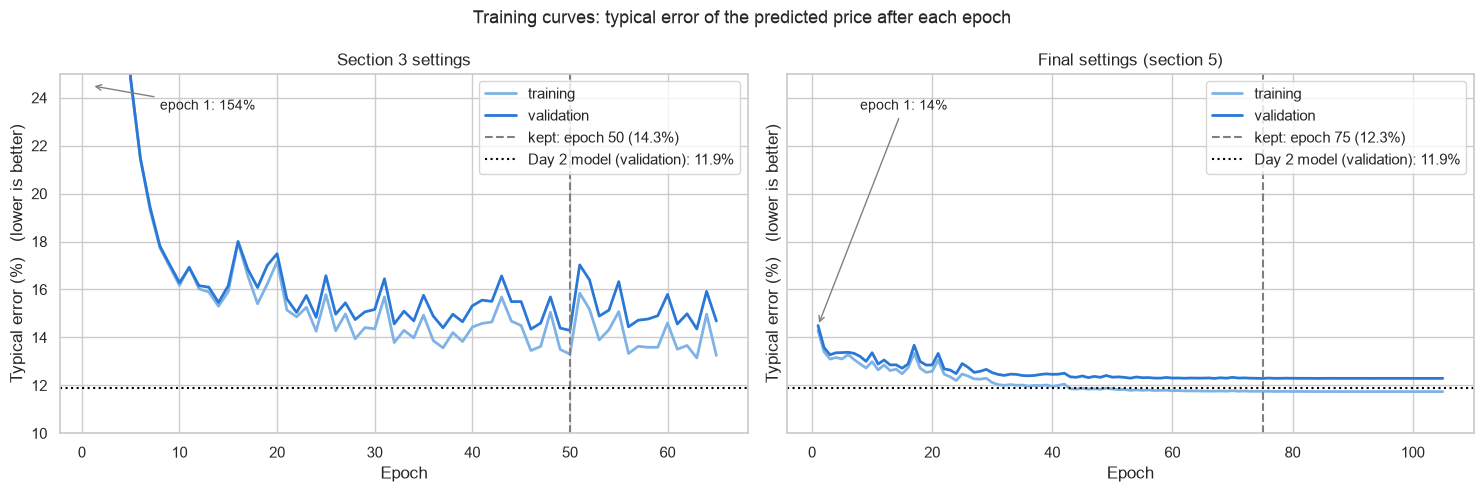

,"dead neurons, section 3 settings","dead neurons, final settings"
hidden layer 1,0 of 64,1 of 64
hidden layer 2,10 of 32,12 of 32


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (title, history) in zip(axes, [("Section 3 settings", section3_history),
                                        ("Final settings (section 5)", final_history)]):
    ax.plot(history.index, history["train error (%)"], label="training", lw=2, color="#7fb2e5")
    ax.plot(history.index, history["validation error (%)"], label="validation", lw=2, color="#2a78d6")
    best = history["validation error (%)"].idxmin()
    ax.axvline(best, color="grey", ls="--", label=f"kept: epoch {best} ({history.loc[best, 'validation error (%)']:.1f}%)")
    ax.axhline(day2_val_error, color="black", ls=":", label=f"Day 2 model (validation): {day2_val_error:.1f}%")
    first = history["validation error (%)"].iloc[0]
    ax.annotate(f"epoch 1: {first:.0f}%", xy=(1, min(first, 24.5)), xytext=(8, 23.5),
                arrowprops={"arrowstyle": "->", "color": "grey"}, fontsize=10)
    ax.set(title=title, xlabel="Epoch", ylabel="Typical error (%)   (lower is better)", ylim=(10, 25))
    ax.legend(loc="upper right")
fig.suptitle("Training curves: typical error of the predicted price after each epoch", fontsize=13)
plt.tight_layout()
save_fig("06_training_curves_final", also_to_models=True)
plt.show()

pd.DataFrame({"dead neurons, section 3 settings": dead_neurons(model, X_val_t),
              "dead neurons, final settings": dead_neurons(final_model, X_val_t)})

**Reading.**

- **The training curves (figure above).** With the section 3 settings, the error starts at about 150% (the network predicts about 0 for a price level of 5.7) and then zig-zags around 14-17% with sudden jumps. With the final settings it starts at a sensible level, and after each halving of the learning rate the curves become flat and smooth, at **12.3%**.
- **Overfitting and when to stop.** The training error ends only about 0.5 point below the validation error: the network does not memorise the training houses; it simply cannot go lower with these inputs. Early stopping kept epoch 75 and stopped 30 epochs later, when nothing improved any more.
- **Dead neurons again, but for a different reason.** The final network also has dead neurons in its second layer. A separate check shows that they do not die in epoch 1 any more (that was the problem of section 3): they **switch off gradually**, because weight decay pulls towards 0 the weights of neurons that bring little. This is regularisation doing its job: the network chooses to work with fewer neurons, and its validation error is lower, not higher.

# 6. Test set, once

Everything is decided: the final settings were chosen on the validation set only. We now predict the **4,147 test houses**, the same test set as Day 2, **once**, and put the result next to the two baselines of section 2.

In [31]:
final_model.eval()
with torch.no_grad():
    test_pred_log = final_model(X_test_t.to(EXP_DEVICE)).cpu().numpy().ravel()
day2_test_pred_log = day2_final.predict(X_test)         # the Day 2 model of section 2 (trained on the Day 2 training set)

test_results = pd.concat([
    baseline_results.xs("test", level="evaluated on"),
    pd.DataFrame([evaluate(y_test.to_numpy(), test_pred_log)], index=["Our network (final settings)"]),
])
test_price = 10 ** y_test.to_numpy()
for name, pred in [("Day 2: gradient boosting", day2_test_pred_log), ("Our network (final settings)", test_pred_log)]:
    ratio = 10 ** np.abs(pred - y_test.to_numpy())
    test_results.loc[name, "within ±10% (%)"] = (ratio <= 1.10).mean() * 100
    test_results.loc[name, "within ±20% (%)"] = (ratio <= 1.20).mean() * 100

test_results.style.format({"R² (log10)": "{:.3f}", "MAE (log10)": "{:.4f}", "typical error (%)": "{:.1f}",
                           "MAE (USD)": "{:,.0f}", "within ±10% (%)": "{:.1f}", "within ±20% (%)": "{:.1f}"},
                          na_rep="-")

,R² (log10),MAE (log10),typical error (%),MAE (USD),within ±10% (%),within ±20% (%)
Dummy (mean price),-0.000,0.1674,47.0,"196,281",-,-
Day 2: gradient boosting,0.886,0.0499,12.2,"60,201",55.8,80.6
Our network (final settings),0.877,0.0515,12.6,"62,682",54.5,79.7


Figure saved to ../figures/07_test_predicted_vs_actual.png
Figure saved to ../models/07_test_predicted_vs_actual.png


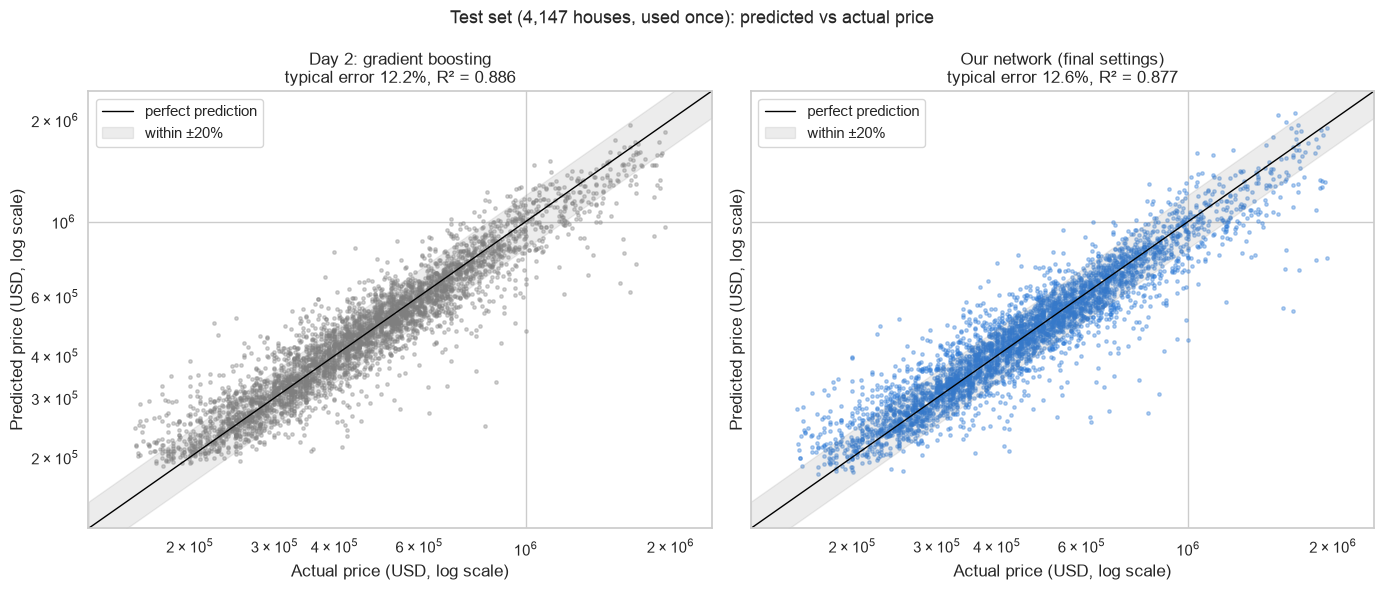

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
lims = [test_price.min() * 0.8, test_price.max() * 1.25]
for ax, (name, pred), color in zip(axes, [("Day 2: gradient boosting", day2_test_pred_log),
                                          ("Our network (final settings)", test_pred_log)], ["#7f7f7f", "#2a78d6"]):
    ax.scatter(test_price, 10 ** pred, s=6, alpha=0.35, color=color)
    ax.plot(lims, lims, color="black", lw=1, label="perfect prediction")
    ax.fill_between(lims, [l / 1.2 for l in lims], [l * 1.2 for l in lims], color="grey", alpha=0.15,
                    label="within ±20%")
    ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
           title=f"{name}\ntypical error {test_results.loc[name, 'typical error (%)']:.1f}%, "
                 f"R² = {test_results.loc[name, 'R² (log10)']:.3f}",
           xlabel="Actual price (USD, log scale)", ylabel="Predicted price (USD, log scale)")
    ax.legend(loc="upper left")
fig.suptitle("Test set (4,147 houses, used once): predicted vs actual price", fontsize=13)
plt.tight_layout()
save_fig("07_test_predicted_vs_actual", also_to_models=True)
plt.show()

Figure saved to ../figures/08_test_error_by_price_band.png
Figure saved to ../models/08_test_error_by_price_band.png


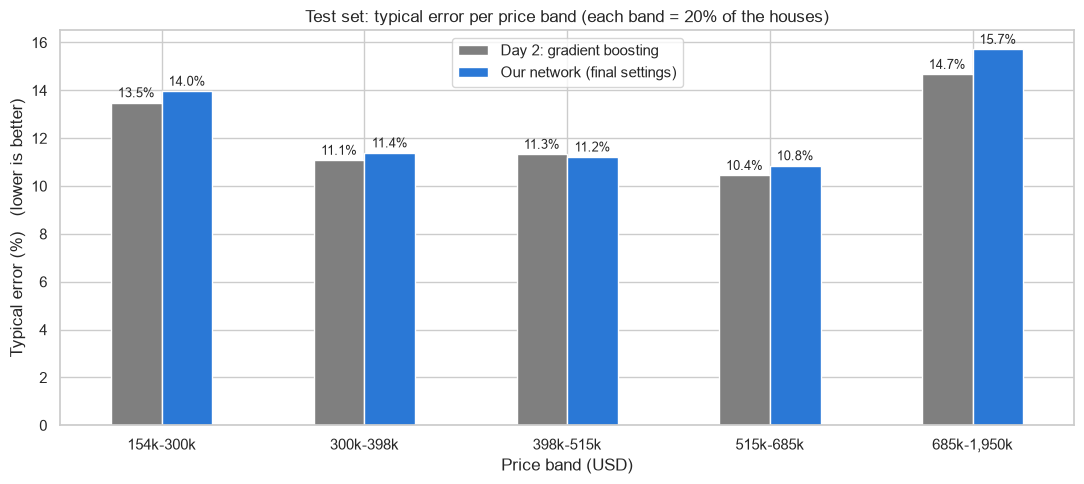

The network is closer to the true price than the Day 2 model for 48% of the test houses.


,Dummy (mean price),Day 2: gradient boosting,Our network (final settings)
154k-300k,89.700,13.500,14.000
300k-398k,32.500,11.100,11.400
398k-515k,6.800,11.300,11.200
515k-685k,28.300,10.400,10.800
"685k-1,950k",101.200,14.700,15.700


In [33]:
test_bands = price_bands(test_price)
test_by_band = errors_by_band(y_test, {"Dummy (mean price)": np.full(len(y_test), y_train.mean()),
                                       "Day 2: gradient boosting": day2_test_pred_log,
                                       "Our network (final settings)": test_pred_log}, test_bands)

fig, ax = plt.subplots(figsize=(11, 5))
test_by_band.drop(columns="Dummy (mean price)").plot.bar(ax=ax, color=["#7f7f7f", "#2a78d6"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, padding=2)
ax.set(title="Test set: typical error per price band (each band = 20% of the houses)",
       xlabel="Price band (USD)", ylabel="Typical error (%)   (lower is better)")
plt.tight_layout()
save_fig("08_test_error_by_price_band", also_to_models=True)
plt.show()

closer = np.abs(test_pred_log - y_test.to_numpy()) < np.abs(day2_test_pred_log - y_test.to_numpy())
print(f"The network is closer to the true price than the Day 2 model for {closer.mean():.0%} of the test houses.")
test_by_band.round(1)

**Reading.**

- **The network does not beat the Day 2 model, but comes close.** On the test set it is typically **12.6% off** the true price (R² = 0.877, mean error 62,700 USD), against **12.2%** (R² = 0.886, 60,200 USD) for gradient boosting and 47.0% for the dummy model. The gap is 0.4 point, or about 2,500 USD on an average house.
- **The test confirms the validation.** On validation the network was 0.4 point behind the Day 2 model (12.3% against 11.9%), and it is 0.4 point behind on the test set too: our many experiments did not overfit the validation set.
- **For a single house, the two models are equally good**: the network is closer to the true price for 48% of the test houses, and both put about 55% of the houses within ±10% and 80% within ±20%. The difference comes from the hardest houses.
- **Where it loses:** in the middle of the market (300,000 - 685,000 USD) the network is as good as gradient boosting (it is even slightly better between 398,000 and 515,000 USD). It loses at both ends, especially for **expensive houses** (15.7% against 14.7%), which are the rarest in the training data.
- **A fairness note on this comparison:** the Day 2 model was trained on the whole Day 2 training set (16,556 sales), while the network only learned from 13,244 of them, because it needs the other 3,312 for early stopping. The network therefore had 20% less data.

**Answer to the question of this project:** for this tabular data, **a neural network does not beat our Day 2 gradient boosting model**. It is 4% (relative) worse, harder to train (it needed 27 experiments (81 training runs) to get there, against default settings for gradient boosting) and slower. For a first price estimate, we would still recommend the Day 2 model; the network is a credible second opinion.

## Hand-off to sections 7-9

- **`final_model`**: the trained network (on the CPU, in evaluation mode). Its architecture is built by `make_mlp(**{k: FINAL_SETTINGS[k] for k in ["hidden", "dropout", "bias_init"]})`; the model card needs this code, because a `state_dict` only holds the weights.
- **`preprocess`**: the fitted scaler + one-hot encoder (save it with `joblib.dump`). A new house must go through `preprocess.transform(...)` before the network, and the output is `log10(price)`: the price is `10 ** output`.
- **`FINAL_SETTINGS`**, **`final_history`**: the settings and the training curves, for the model card.
- **`test_results`**, **`test_by_band`**: the test results. **Do not evaluate on the test set again.**
- Figures for the model card are already in `models/`: `06_training_curves_final.png`, `07_test_predicted_vs_actual.png`, `08_test_error_by_price_band.png`.